In [1]:
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

for z in [-3, 0, 3]:
    print(f'z={z:>2}  sigmoid={sigmoid(z):.4f}')


z=-3  sigmoid=0.0474
z= 0  sigmoid=0.5000
z= 3  sigmoid=0.9526


In [2]:
x1 = 2.0
x2 = 1.5
b0 = -1.0
b1 = 0.8
b2 = 0.5

z = b0 + b1*x1 + b2*x2
probability = sigmoid(z)
predicted_class = 1 if probability >= 0.5 else 0

print('z =', z)
print('Probability of class 1 =', round(probability, 4))
print('Predicted class =', predicted_class)


z = 1.35
Probability of class 1 = 0.7941
Predicted class = 1


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
print('Dataset loaded successfully.')
display(df.head())
print('Target names:', data.target_names)


Dataset loaded successfully.


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Target names: ['malignant' 'benign']


In [5]:
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
df.info()
display(df.describe().T)
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Class counts:')
print(df['target'].value_counts().sort_index())

Shape: (569, 31)
Columns: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean are

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Missing values: 0
Duplicate rows: 0
Class counts:
target
0    212
1    357
Name: count, dtype: int64


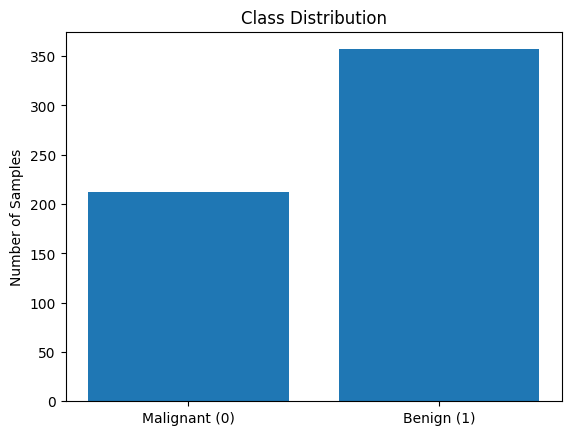

In [6]:
class_counts = df['target'].value_counts().sort_index()
plt.bar(['Malignant (0)', 'Benign (1)'], class_counts.values)
plt.ylabel('Number of Samples')
plt.title('Class Distribution')
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Training class proportions:')
print(y_train.value_counts(normalize=True).sort_index())

Training rows: 455
Testing rows: 114
Training class proportions:
target
0    0.373626
1    0.626374
Name: proportion, dtype: float64


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Scaled training shape:', X_train_scaled.shape)


Scaled training shape: (455, 30)


In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print('Intercept:', model.intercept_[0])
print('Number of coefficients:', len(model.coef_[0]))


Intercept: 0.30220757353702
Number of coefficients: 30


In [10]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]
y_pred = model.predict(X_test_scaled)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Probability_Class_1': y_prob,
    'Predicted': y_pred
})
display(results.head(10))


,Actual,Probability_Class_1,Predicted
0,0,5.888242e-08,0
1,1,9.999887e-01,1
2,0,6.410825e-03,0
3,1,5.335085e-01,1
4,0,6.525001e-10,0
5,1,9.921604e-01,1
6,1,9.999828e-01,1
7,0,5.635275e-07,0
8,0,5.431637e-05,0
9,0,8.041849e-11,0


In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f'Accuracy:  {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall:    {recall:.4f}')
print(f'F1-score:  {f1:.4f}')


Accuracy:  0.9825
Precision: 0.9861
Recall:    0.9861
F1-score:  0.9861


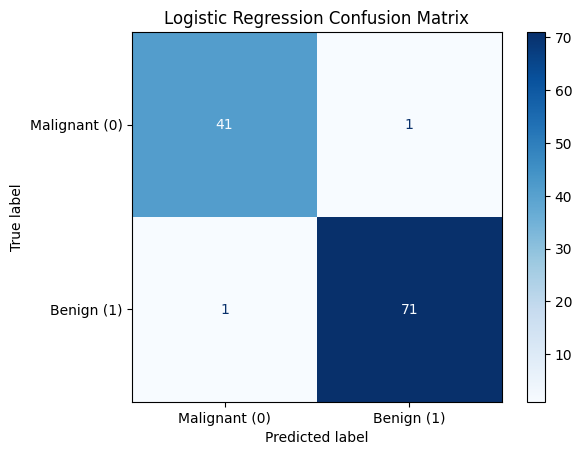

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Malignant (0)', 'Benign (1)'],
    cmap='Blues'
)
plt.title('Logistic Regression Confusion Matrix')
plt.show()


In [14]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test, y_pred,
    target_names=['Malignant', 'Benign']
))


              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [15]:
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    pred_t = (y_prob >= threshold).astype(int)
    threshold_rows.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, pred_t),
        'Precision': precision_score(y_test, pred_t),
        'Recall': recall_score(y_test, pred_t),
        'F1': f1_score(y_test, pred_t)
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))


,Threshold,Accuracy,Precision,Recall,F1
0,0.3,0.9825,0.9730,1.0000,0.9863
1,0.5,0.9825,0.9861,0.9861,0.9861
2,0.7,0.9474,0.9853,0.9306,0.9571


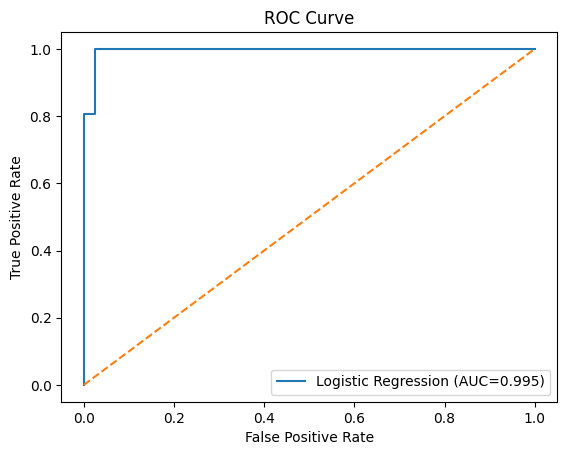

ROC-AUC: 0.9954


In [17]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()
print(f'ROC-AUC: {auc:.4f}')


In [18]:
coef_table = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})
coef_table['AbsCoefficient'] = coef_table['Coefficient'].abs()
coef_table = coef_table.sort_values('AbsCoefficient', ascending=False)
display(coef_table.head(10))


,Feature,Coefficient,AbsCoefficient
21,worst texture,-1.255088,1.255088
10,radius error,-1.082965,1.082965
27,worst concave points,-0.953686,0.953686
23,worst area,-0.947756,0.947756
20,worst radius,-0.947616,0.947616
28,worst symmetry,-0.939181,0.939181
13,area error,-0.929104,0.929104
26,worst concavity,-0.823151,0.823151
22,worst perimeter,-0.763220,0.763220
24,worst smoothness,-0.746625,0.746625


In [20]:
sample = X_test.iloc[[0]]
sample_scaled = scaler.transform(sample)
prob_benign = model.predict_proba(sample_scaled)[0, 1]
pred_class = model.predict(sample_scaled)[0]

print('Actual class:', y_test.iloc[0])
print(f'Probability of benign (class 1): {prob_benign:.4f}')
print('Predicted class:', pred_class)
print('Predicted label:', data.target_names[pred_class])

Actual class: 0
Probability of benign (class 1): 0.0000
Predicted class: 0
Predicted label: malignant
